# Bina.az yaşayış əmlakı: yekun ML layihəsi
**Özümüz yazdığımız Decision Tree, linear Pegasos SVM və RFF + Pegasos**

Bu notebook hazır nəticələri izah edir və saxlanmış modellə proqnoz verir. Sıra ilə **Run All** et.
Uzun təlimi təkrarlamaq üçün ikinci kod hüceyrəsində `RUN_FULL_EXPERIMENT=True` seç.
Standart rejimdə təlim yenidən başlamır. Python 3.12 və `requirements.txt` paketləri tələb olunur.

**İki ayrı tapşırıq:** (1) elanın qiymətini AZN ilə proqnozlaşdırmaq; (2) qiymətin təlim medianından yüksək olub-olmadığını tapmaq.
F1 qiymətin neçə faiz dəqiq hesablandığını göstərmir.

Tam izah: `report/report.pdf` · Təqdimat: `presentation/ML_Final_Slides.pdf` · Müdafiə: `DEFENSE_GUIDE_AZ.md`

Müəllif adları və real GitHub ünvanı hələ komanda tərəfindən doldurulmalıdır. AI yardımı `AI_DISCLOSURE.md` faylında açıqlanıb.

In [2]:
%pip install --upgrade --force-reinstall --no-cache-dir -r requirements.txt


   ---------------------------------------- 0.0/12.8 MB ? eta -:--:--
   ---- ----------------------------------- 1.3/12.8 MB 9.5 MB/s eta 0:00:02
   -------------------- ------------------- 6.6/12.8 MB 19.2 MB/s eta 0:00:01
   ------------------------------------ --- 11.5/12.8 MB 24.9 MB/s eta 0:00:01
   ---------------------------------------- 12.8/12.8 MB 22.9 MB/s eta 0:00:00
   ---------------------------------------- 0.0/11.5 MB ? eta -:--:--
   --------------------------- ------------ 7.9/11.5 MB 37.4 MB/s eta 0:00:01
   ---------------------------------------- 11.5/11.5 MB 37.9 MB/s eta 0:00:00
   ---------------------------------------- 0.0/8.1 MB ? eta -:--:--
   ---------------------------------- ----- 7.1/8.1 MB 33.4 MB/s eta 0:00:01
   ---------------------------------------- 8.1/8.1 MB 26.5 MB/s eta 0:00:00
   ---------------------------------------- 0.0/8.0 MB ? eta -:--:--
   ---------------------------------------- 8.0/8.0 MB 41.3 MB/s eta 0:00:00
   ------------------

  You can safely remove it manually.
  You can safely remove it manually.
  You can safely remove it manually.
  You can safely remove it manually.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gensim 4.3.3 requires numpy<2.0,>=1.18.5, but you have numpy 2.3.5 which is incompatible.
gensim 4.3.3 requires scipy<1.14.0,>=1.7.0, but you have scipy 1.17.0 which is incompatible.
numba 0.60.0 requires numpy<2.1,>=1.22, but you have numpy 2.3.5 which is incompatible.
streamlit 1.37.1 requires packaging<25,>=20, but you have packaging 26.3 which is incompatible.
streamlit 1.37.1 requires pillow<11,>=7.1.0, but you have pillow 13.0.0 which is incompatible.
streamlit 1.37.1 requires protobuf<6,>=3.20, but you have protobuf 6.33.5 which is incompatible.


In [3]:
from pathlib import Path
import sys, json, hashlib, subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve()
if not (ROOT / 'src').is_dir():
    candidates = [ROOT / 'ML_Final_Project', ROOT.parent]
    ROOT = next((p for p in candidates if (p / 'src').is_dir()), ROOT)
assert (ROOT / 'src').is_dir(), 'Notebooku ML_Final_Project qovluğundan aç.'
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
OUT = ROOT / 'outputs'
def read_json(path):
    return json.loads(Path(path).read_text(encoding='utf-8'))
def show_figure(filename):
    img = plt.imread(ROOT / 'report' / 'figures' / filename)
    h, w = img.shape[:2]
    fig, ax = plt.subplots(figsize=(12, 12 * h / w))
    ax.imshow(img)
    ax.axis('off')
    fig.tight_layout(pad=0.1)
    plt.show()
print('Python:', sys.version.split()[0])
print('Project:', ROOT.name)
print('NumPy:', np.__version__, '| pandas:', pd.__version__)

Python: 3.12.7
Project: ML_Final_Project
NumPy: 2.3.5 | pandas: 2.2.3


## 1. Təkrar icra və məlumatın yoxlanması
`False` hazır nəticələri açır. `True` eyni CSV-dən axtarış, 5-fold CV və test mərhələlərini yenidən işlədir.
İlkin icra təxminən 9 dəqiqə çəkib; kompüterdən asılıdır və bir neçə GB boş RAM lazımdır.
Test nəticəsinə baxıb parametr dəyişmək düzgün müqayisəni pozar. Seçim **validation** üzərində edilib.

In [4]:
RUN_FULL_EXPERIMENT = False
if RUN_FULL_EXPERIMENT:
    subprocess.run([sys.executable, '-m', 'src.run_all'], cwd=ROOT, check=True)
config = read_json(OUT / 'frozen_config.json')
summary = read_json(OUT / 'final_data_summary.json')
data_path = ROOT / 'data' / 'house_sale.csv'
assert data_path.is_file(), 'house_sale.csv faylını data qovluğuna qoy.'
with data_path.open('rb') as f:
    actual_hash = hashlib.file_digest(f, 'sha256').hexdigest()
assert actual_hash == config['dataset_sha256'], 'CSV dəyişib; hazır nəticələr bu CSV-yə aid deyil.'
metrics = pd.DataFrame(read_json(OUT / 'final_metrics.json'))
test = metrics.query("subset == 'test'").set_index('model')
print('CSV SHA256 uyğun gəlir.')
print('Seçim:', config['selection'])
print('Konfiqurasiya SHA256:', config['configuration_sha256'])

CSV SHA256 uyğun gəlir.
Seçim: Validation RMSE for regression; positive-class F1 for classification. No test selection.
Konfiqurasiya SHA256: e4d29a6f7ae7a3852838b512ca8a27ad00f240d0465025e92af06afe27febd8f


## 2. Dataset və sızmanın qarşısı
Ofis, obyekt, torpaq və qaraj çıxarılıb. Yeni tikili, köhnə tikili və həyət/bağ evi qalıb.
Təkrar elanların son versiyası saxlanıb; ehtimal olunan dublikat qrupları bölmələr arasında paylaşılmır.
İmputasiya, kateqoriya kodlaması, standartlaşdırma və coğrafi mərkəzlər yalnız təlimdə öyrənilir.
Qiymətdən törəyən sütunlar, ID və sərbəst mətn modelə verilmir.

Premium sinfi: **price > 207 000 AZN**. Bu hədd yalnız yaşayış tipli təlim məlumatının medianıdır.

Xam sətirlər: 100775
Son versiya saxlandıqdan sonra: 64454
Yaşayış əmlakı: 58452
                n  groups  premium
train       40932   40422    20430
validation   8796    8692     4490
test         8724    8622     4435
Kateqoriyalar: yeni tikili, köhnə tikili, həyət evi/bağ evi
Kodlanmış giriş sütunları: 141
Premium həddi: 207000.0 AZN


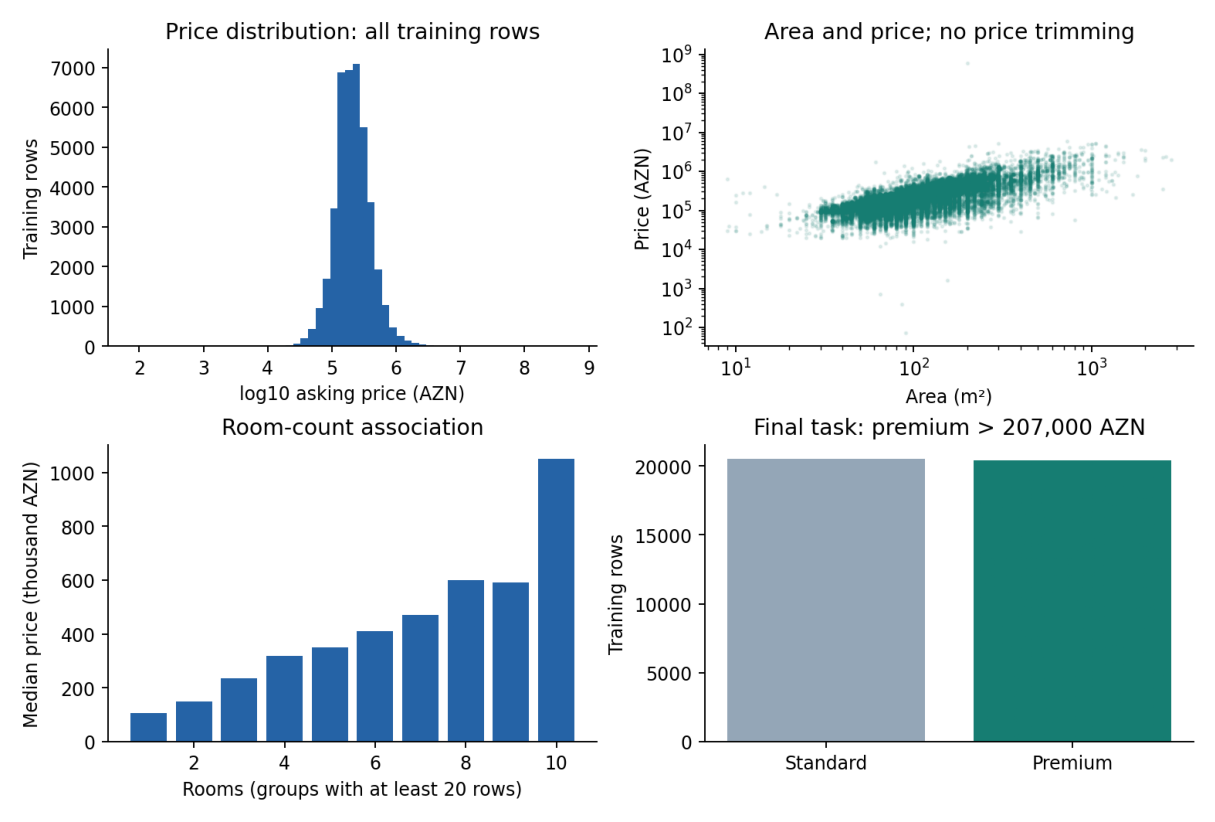

In [5]:
print('Xam sətirlər:', summary['raw_rows'])
print('Son versiya saxlandıqdan sonra:', summary['clean_rows'])
print('Yaşayış əmlakı:', summary['residential_rows'])
print(pd.DataFrame(summary['split']).T.to_string())
print('Kateqoriyalar:', ', '.join(summary['categories']))
print('Kodlanmış giriş sütunları:', summary['feature_count'])
print('Premium həddi:', summary['threshold'], 'AZN')
show_figure('final_eda.png')

## 3. Tələb olunan modellər və seçim
- **Decision Tree:** NumPy ilə Gini / entropy / MSE, dəqiq split axtarışı, dərinlik və minimum yarpaq ölçüsü.
- **Pegasos:** hinge loss + L2, mini-batch subgradient, `eta_t = 1 / (lambda * t)`, proyeksiya və iteratların ortalaması.
- **RFF + Pegasos:** öz Random Fourier Features xəritəsi ilə qeyri-xətti RBF nüvəsinin yaxınlaşdırılması.
- **sklearn:** eyni girişlər və uyğun parametrlərlə istinad müqayisəsi.

Regressiya validation RMSE, təsnifat validation F1 ilə seçilib. Regressiyada log-qiymət və ayrı mənzil/həyət-evi ağacları istifadə olunur.
Yekun modellər ilkin train-də öyrədilib; validation sonradan train-ə əlavə edilməyib.

Regressiya seçimi:
{
  "name": "own_spatial_segmented",
  "kind": "own_tree",
  "spatial": true,
  "segmented": true,
  "audit_filter": false,
  "reviewed_training": false,
  "max_depth": 16,
  "min_samples_leaf": 5,
  "iterations": 300,
  "max_leaf_nodes": 31,
  "l2": 1.0
}
Təsnifat parametrləri:
{
  "tree": {
    "kind": "tree",
    "criterion": "entropy",
    "max_depth": 16,
    "min_samples_leaf": 10
  },
  "linear": {
    "kind": "linear",
    "lambda_": 0.001,
    "n_epochs": 120,
    "schedule": "pegasos"
  },
  "rff": {
    "kind": "rff",
    "gamma": 0.005,
    "n_components": 2048,
    "lambda_": 1e-05,
    "n_epochs": 120,
    "schedule": "pegasos"
  }
}
Validation üzrə qalib: tree
            model     f1  roc_auc
         own_tree 0.9253   0.9688
     sklearn_tree 0.9255   0.9688
       own_linear 0.9095   0.9700
   sklearn_linear 0.9088   0.9697
          own_rff 0.9136   0.9732
      sklearn_rff 0.9136   0.9733
training_majority 0.0000   0.5000


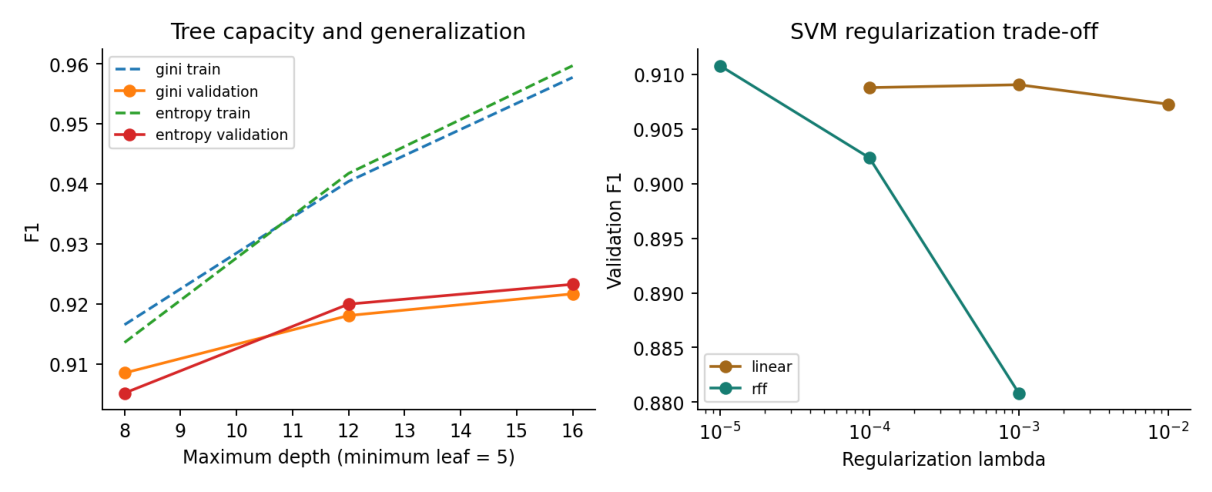

In [6]:
print('Regressiya seçimi:')
print(json.dumps(config['regression'], ensure_ascii=False, indent=2))
print('Təsnifat parametrləri:')
print(json.dumps(config['classification'], ensure_ascii=False, indent=2))
print('Validation üzrə qalib:', config['classification_winner'])
val = metrics.query("subset == 'validation' and task == 'classification'")
print(val[['model', 'f1', 'roc_auc']].to_string(index=False, float_format=lambda x: f'{x:.4f}'))
show_figure('final_tuning.png')

## 4. Görülməmiş test: təsnifat
Test hissəsi 8 724 elandır. Öz Decision Tree modelinin F1-i təxminən **0.9218**-dir.
RFF modelinin ROC AUC-u daha yüksək olsa da, model seçimi əvvəldən F1 üzrə müəyyənləşdirilib.
Qarışıqlıq matrisində sətirlər həqiqi, sütunlar proqnoz sinifləridir.

                   precision  recall     f1  roc_auc  pr_auc_ap
model                                                          
own_tree              0.9294  0.9143 0.9218   0.9670     0.9603
sklearn_tree          0.9307  0.9141 0.9223   0.9676     0.9612
own_linear            0.9058  0.9017 0.9037   0.9671     0.9673
sklearn_linear        0.9062  0.9001 0.9032   0.9670     0.9666
own_rff               0.9129  0.9048 0.9088   0.9716     0.9722
sklearn_rff           0.9146  0.9051 0.9098   0.9717     0.9723
training_majority     0.0000  0.0000 0.0000   0.5000     0.5084
Own tree confusion matrix:
                 Pred standard  Pred premium
Actual standard           3981           308
Actual premium             380          4055


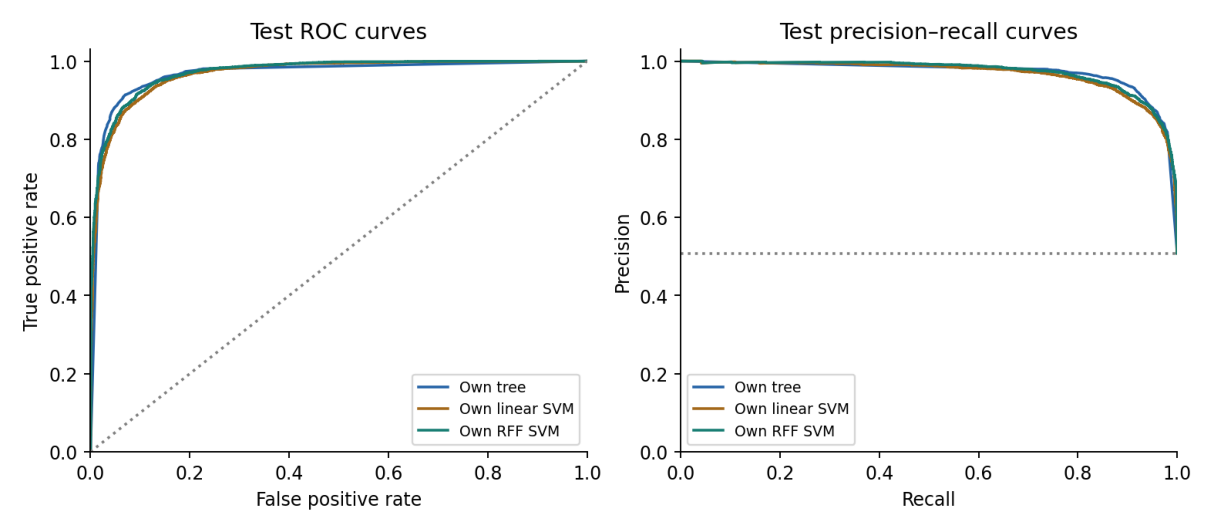

In [7]:
classification = test.query("task == 'classification'")
print(classification[['precision', 'recall', 'f1', 'roc_auc', 'pr_auc_ap']].to_string(float_format=lambda x: f'{x:.4f}'))
cm = np.asarray(test.loc['own_tree', 'confusion_matrix'])
print('Own tree confusion matrix:')
print(pd.DataFrame(cm, index=['Actual standard', 'Actual premium'], columns=['Pred standard', 'Pred premium']).to_string())
show_figure('final_roc_pr.png')

## 5. Görülməmiş test: qiymət proqnozu
Median faiz xətası tipik proqnozu, RMSE isə böyük xətalara həssas nəticəni göstərir.
**MedAPE 8.74%**, proqnozların **77.38%-i ±20%** daxilindədir. Amma **R² ≈ 0.104 zəifdir**.
Bu səbəbdən modeli bütün qiymət aralığında yüksək dəqiqlikli qiymətləndirici kimi təqdim etmək olmaz.
Elan qiyməti real satış qiyməti deyil.

                                rmse          mae      r2  median_ape_pct  within_20_pct
model                                                                                   
own_tree_regression     667,506.7910  56,567.5826  0.1037          8.7416        77.3842
sklearn_tree_regression 666,545.4266  56,592.3198  0.1063          8.7122        77.4415
training_median         708,732.4245 140,926.7769 -0.0105         39.1176        26.5475
Ən böyük 1% xətanın ümumi kvadrat xətada payı: 98.84 %
Testdən çıxarılan sətir: 0


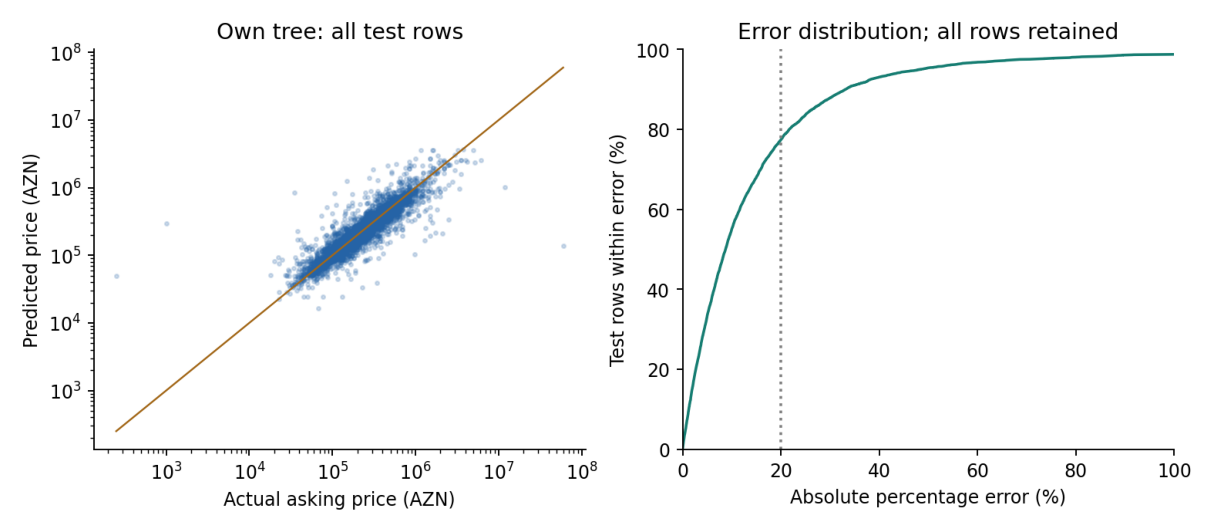

In [8]:
regression = test.query("task == 'regression'")
print(regression[['rmse', 'mae', 'r2', 'median_ape_pct', 'within_20_pct']].to_string(float_format=lambda x: f'{x:,.4f}'))
errors = read_json(OUT / 'final_error_analysis.json')
print('Ən böyük 1% xətanın ümumi kvadrat xətada payı:', round(100 * errors['top_one_percent_sse_share'], 2), '%')
print('Testdən çıxarılan sətir:', errors['rows_removed_from_evaluation'])
show_figure('final_regression.png')

## 6. Ayrı 5-fold GroupKFold
Bu yoxlama yalnız ilkin training hissəsində aparılıb və hər fold-da preprocessing yenidən öyrənilib.
Sabit seçilmiş parametrlərin dəyişkənliyini ölçür; nested CV və ya test nəticəsi üçün etibar intervalı deyil.
600 milyon AZN-lik yoxlanılmamış təlim etiketi bir CV fold-unun RMSE-sini çox böyüdür.
Həmin nəticə gizlədilməyib. Premium həddi əvvəlcədən müəyyənləşdirilmiş 207 000 AZN olaraq qalır.

Classification CV (mean / std):
                f1_mean  f1_std  roc_auc_mean  roc_auc_std
model                                                     
own_linear       0.9061  0.0038        0.9689       0.0023
own_rff          0.9111  0.0023        0.9721       0.0022
own_tree         0.9183  0.0023        0.9669       0.0021
sklearn_linear   0.9061  0.0043        0.9686       0.0022
sklearn_rff      0.9114  0.0024        0.9722       0.0021
sklearn_tree     0.9185  0.0024        0.9673       0.0023
Regression CV (mean / std):
                           rmse_mean     rmse_std  median_ape_pct_mean  median_ape_pct_std
model                                                                                     
own_tree_regression      1431886.058  2904140.945                9.222               0.054
sklearn_tree_regression  1434084.342  2902904.690                9.220               0.038


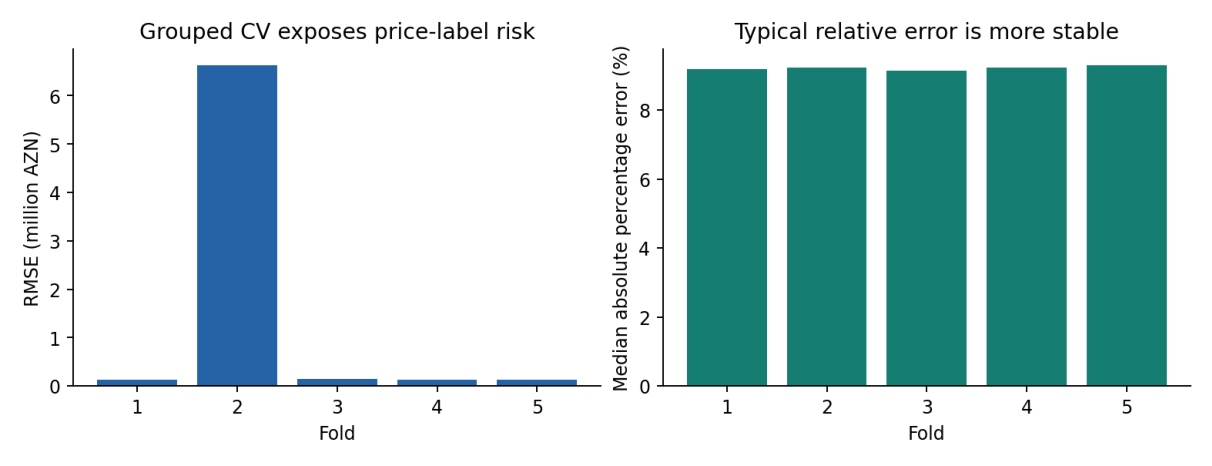

In [9]:
cv = pd.read_csv(OUT / 'final_cv_summary.csv').set_index('model')
print('Classification CV (mean / std):')
print(cv.query("task == 'classification'")[['f1_mean', 'f1_std', 'roc_auc_mean', 'roc_auc_std']].round(4).to_string())
print('Regression CV (mean / std):')
print(cv.query("task == 'regression'")[['rmse_mean', 'rmse_std', 'median_ape_pct_mean', 'median_ape_pct_std']].round(3).to_string())
show_figure('final_cv_stability.png')

## 7. SVM-in həqiqi optimizasiya diaqnostikası
Məqsəd: `lambda/2 * ||w||² + mean(max(0, 1 - y * (Xw+b)))`.
Bias ayrıca saxlanır və regularizasiya olunmur. Həndəsi margin eni `2 / ||w||` ilə verilir.
`signed margin <= 1` siyahısı margin daxilindəki / səhv təsnif edilən təlim nümunələridir;
bu, ayrıca dual həllin dəqiq support-vector siyahısı kimi şərh edilməməlidir.
Stoxastik optimizasiyada objective hər addımda monoton azalmalı deyil.

     model  objective  weight_norm  margin_width  margin_violator_fraction  margin_violator_count  n_steps
own_linear   0.238013     3.575187      0.559411                  0.242207                   9914    19200
   own_rff   0.226110    60.817459      0.032885                  0.212499                   8698    19200


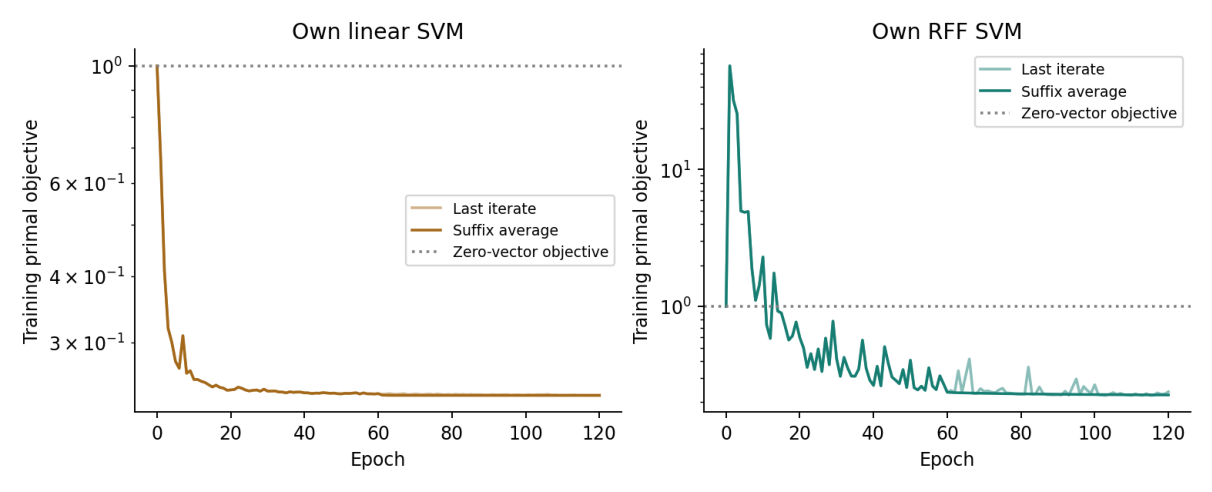

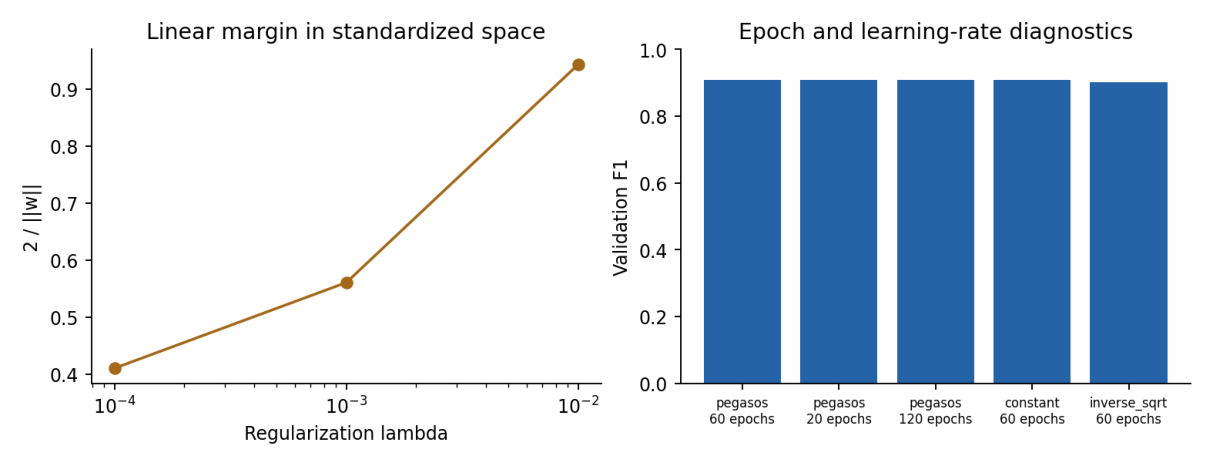

In [10]:
diagnostics = pd.read_csv(OUT / 'svm_diagnostics.csv')
print(diagnostics.to_string(index=False))
show_figure('final_svm_objective.png')
show_figure('final_margin_schedule.png')

## 8. Model harada daha çox yanılır?
Həyət/bağ evlərində qiymət xətası mənzillərdən yüksəkdir. Premium həddinə yaxın elanların sinfini seçmək daha çətindir.
Bütün test sətirləri saxlanılıb; yüksək xəta verdiyi üçün elan silinməyib.
Ekstremal qiymətlərin səhv məlumat olub-olmadığı ayrıca mənbə yoxlaması olmadan təsdiqlənə bilməz.

In [11]:
print('Kateqoriya üzrə regressiya:')
print(pd.read_csv(OUT / 'final_regression_error_by_category.csv').round(3).to_string(index=False))
print('Təsnifat səhvlərinin qrupları:')
print(pd.read_csv(OUT / 'final_classification_error_groups.csv').round(4).to_string(index=False))
print('Maksimum train qiyməti:', f"{errors['train_max_price']:,.0f}", 'AZN')
print('Maksimum test qiyməti:', f"{errors['test_max_price']:,.0f}", 'AZN')

Kateqoriya üzrə regressiya:
         category    n       rmse        mae    r2  median_ape_pct  within_20_pct
həyət evi/bağ evi 1451 402336.682 123771.232 0.469          19.800         50.310
     köhnə tikili 1859  64548.154  20849.200 0.408           7.966         83.486
      yeni tikili 5414 820463.034  50820.995 0.052           7.500         82.545
Təsnifat səhvlərinin qrupları:
     model         group_type                     group    n  error_rate  precision  recall     f1  roc_auc  pr_auc_ap  accuracy
  own_tree           category         həyət evi/bağ evi 1451      0.1082     0.9096  0.8795 0.8943   0.9561     0.9534    0.8918
  own_tree           category              köhnə tikili 1859      0.0742     0.8024  0.6910 0.7425   0.9281     0.7769    0.9258
  own_tree           category               yeni tikili 5414      0.0726     0.9430  0.9410 0.9420   0.9666     0.9715    0.9274
  own_tree threshold_distance    farther_from_threshold 7683      0.0517     0.9550  0.9436 0.949

## 9. Şərh edilə bilmə və coğrafiya
Ağacın feature importance nəticələri səbəb-nəticə sübutu deyil. Korrelyasiyalı əlamətlər bir-birinin çəkisini azalda bilər.
Linear SVM çəkiləri standartlaşdırılmış girişlərə aiddir; kateqoriyaların kodlanmasını nəzərə almaq lazımdır.
Coğrafi k-means mərkəzləri yalnız təlim koordinatları ilə öyrənilib və əlavə məsafə əlamətləri yaradır.

Ağacın ən vacib 10 əlaməti:
              model     route       feature  importance
own_tree_regression apartment       area_m2    0.586214
own_tree_regression apartment  land_area_m2    0.000000
own_tree_regression apartment         rooms    0.001863
own_tree_regression apartment         floor    0.004681
own_tree_regression apartment  total_floors    0.012482
own_tree_regression apartment   floor_ratio    0.009654
own_tree_regression apartment      latitude    0.013308
own_tree_regression apartment     longitude    0.004346
own_tree_regression apartment   log_area_m2    0.141458
own_tree_regression apartment area_per_room    0.004263
Linear SVM çəkiləri (ilk 10 sətir):
      feature  coefficient
      area_m2    -0.476903
 land_area_m2    -0.060618
        rooms    -0.000202
        floor    -0.098962
 total_floors     0.248069
  floor_ratio     0.031977
     latitude    -0.073572
    longitude     0.110537
  log_area_m2     3.158092
area_per_room    -0.164379


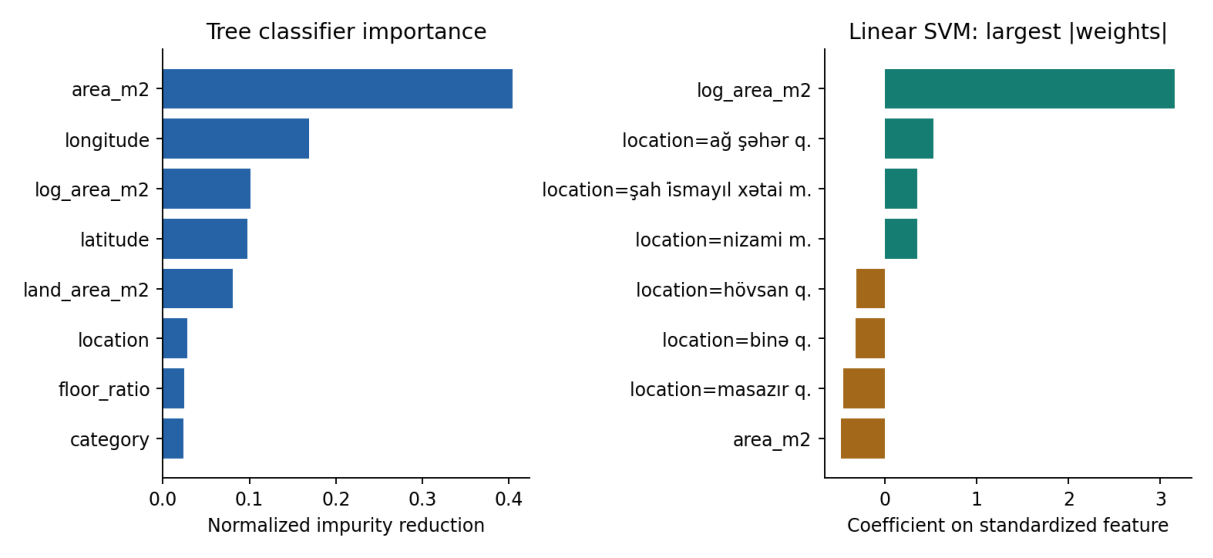

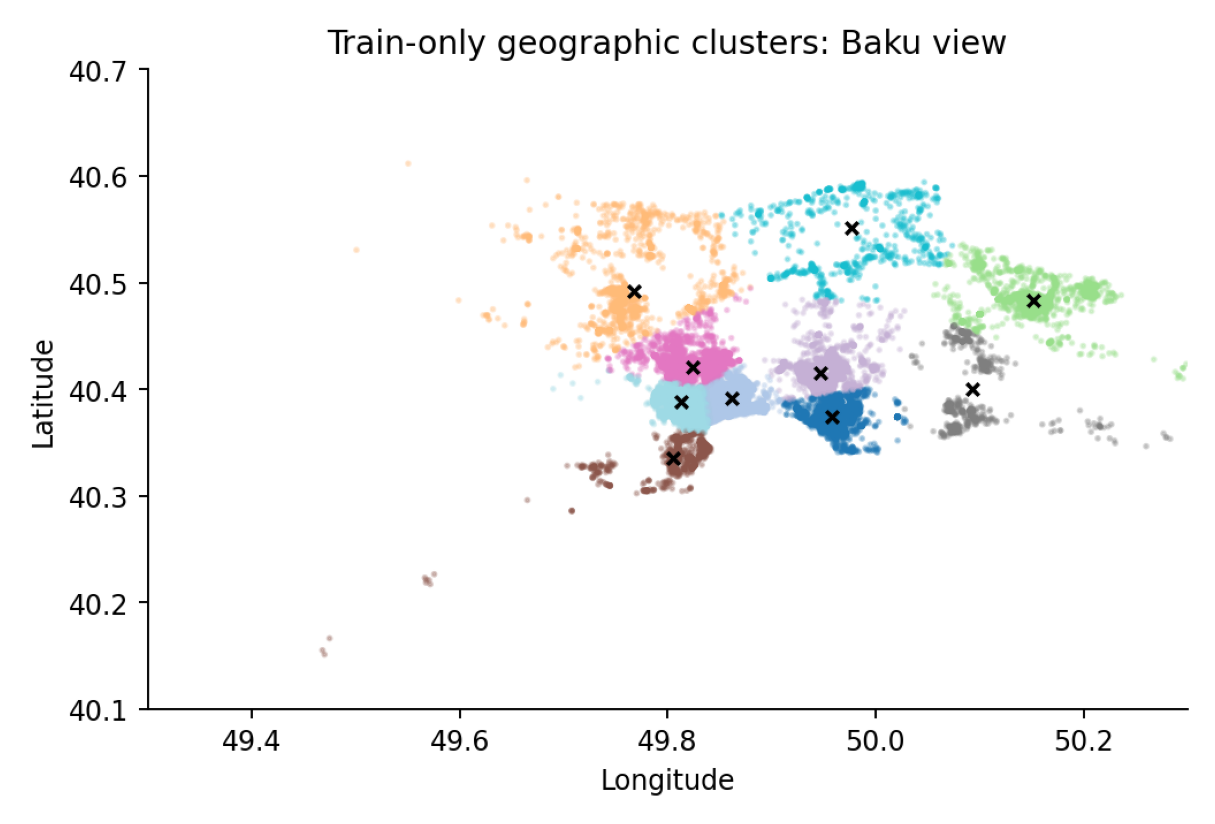

In [12]:
print('Ağacın ən vacib 10 əlaməti:')
print(pd.read_csv(OUT / 'final_feature_importance.csv').head(10).to_string(index=False))
print('Linear SVM çəkiləri (ilk 10 sətir):')
print(pd.read_csv(OUT / 'linear_svm_weights.csv').head(10).to_string(index=False))
show_figure('final_interpretation.png')
show_figure('final_geography.png')

## 10. Öz ev məlumatınla proqnoz
Aşağıdakı nümunəni dəyiş və hüceyrəni yenidən işə sal. Qiymət hədəf sütununu girişə əlavə etmə.
`repair`, `bill_of_sale`, `mortgage`: `var` / `yoxdur`; kateqoriya üç yaşayış tipindən biri olmalıdır.
Nümunə real satış iddiası deyil. Qiymət və premium təsnifat ayrı modellərdir; həddə yaxın hallarda fərqlənə bilərlər.
Yalnız bu paketdəki və ya özün yaratdığın etibarlı model faylını aç.

In [13]:
from src.predict import load_models, predict_listing
example = read_json(ROOT / 'examples' / 'listing.json')
example.update(area_m2=100, rooms=3, floor=7, total_floors=16)
bundle = load_models(ROOT / 'models' / 'final_models.pkl')
print('Giriş:')
print(json.dumps(example, ensure_ascii=False, indent=2))
print('Proqnoz:')
print(json.dumps(predict_listing(example, bundle), ensure_ascii=False, indent=2))

Giriş:
{
  "category": "yeni tikili",
  "city": "Bakı",
  "location": "Yasamal r.",
  "area_m2": 100,
  "rooms": 3,
  "floor": 7,
  "total_floors": 16,
  "latitude": 40.4,
  "longitude": 49.82,
  "repair": "var",
  "bill_of_sale": "var",
  "mortgage": "var"
}
Proqnoz:
{
  "predicted_price_azn": 291566.89,
  "premium_class": "premium",
  "premium_threshold_azn": 207000.0,
  "classifier": "own_tree"
}


In [34]:
import sys
import os
import subprocess
from pathlib import Path

requirements = Path("requirements.txt").resolve()
assert requirements.exists(), "Notebooku ML_Final_Project qovluğunda aç."

env = requirements.parent / ".venv"
python = env / ("Scripts/python.exe" if os.name == "nt" else "bin/python")

def run(command):
    result = subprocess.run(command, capture_output=True, text=True)
    if result.returncode:
        print(result.stdout[-3000:])
        print(result.stderr[-3000:])
        raise RuntimeError("Əməliyyat alınmadı. Yuxarıdakı xətanı göndər.")
    return result.stdout

print("Təmiz mühit yaradılır...")
run([sys.executable, "-m", "venv", str(env)])

print("Layihənin paketləri quraşdırılır. Bir neçə dəqiqə çəkə bilər...")
run([
    str(python), "-m", "pip", "install",
    "-r", str(requirements), "ipykernel"
])

print(run([
    str(python), "-c",
    "import numpy, sklearn; "
    "from sklearn.metrics import f1_score, roc_auc_score, r2_score; "
    "print('Importlar işləyir. NumPy:', numpy.__version__)"
]))

run([
    str(python), "-m", "ipykernel", "install", "--user",
    "--name", "ml_final_fixed",
    "--display-name", "ML Final Fixed"
])

print("Hazırdır! İndi Kernel menyusundan ML Final Fixed seç.")

Təmiz mühit yaradılır...
Layihənin paketləri quraşdırılır. Bir neçə dəqiqə çəkə bilər...

Traceback (most recent call last):
  File "<string>", line 1, in <module>
  File "C:\Users\Baku\anaconda3\Lib\encodings\cp1252.py", line 19, in encode
    return codecs.charmap_encode(input,self.errors,encoding_table)[0]
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
UnicodeEncodeError: 'charmap' codec can't encode character '\u015f' in position 11: character maps to <undefined>



RuntimeError: Əməliyyat alınmadı. Yuxarıdakı xətanı göndər.

In [35]:
import subprocess
from pathlib import Path

python = Path.cwd() / ".venv" / "Scripts" / "python.exe"

commands = [
    [
        str(python), "-X", "utf8", "-c",
        "import numpy, sklearn; "
        "from sklearn.metrics import f1_score, roc_auc_score, r2_score; "
        "print('Imports OK. NumPy:', numpy.__version__)"
    ],
    [
        str(python), "-X", "utf8",
        "-m", "ipykernel", "install", "--user",
        "--name", "ml_final_fixed",
        "--display-name", "ML Final Fixed"
    ]
]

for command in commands:
    result = subprocess.run(
        command,
        capture_output=True,
        encoding="utf-8",
        errors="replace"
    )
    print(result.stdout)
    if result.returncode != 0:
        print(result.stderr)
        raise RuntimeError("Command failed.")

print("Setup complete. Select ML Final Fixed.")

Imports OK. NumPy: 2.3.5

Installed kernelspec ml_final_fixed in C:\Users\Baku\AppData\Roaming\jupyter\kernels\ml_final_fixed

Setup complete. Select ML Final Fixed.


In [15]:
%pip install --upgrade --no-cache-dir --only-binary=:all: pyarrow

   ---------------------------------------- 0.0/28.6 MB ? eta -:--:--
   ---------------------------------------- 0.0/28.6 MB ? eta -:--:--
   -- ------------------------------------- 1.8/28.6 MB 9.1 MB/s eta 0:00:03
   ------------- -------------------------- 9.4/28.6 MB 23.5 MB/s eta 0:00:01
   ---------------------- ----------------- 15.7/28.6 MB 26.8 MB/s eta 0:00:01
   ---------------------------------------  28.3/28.6 MB 33.9 MB/s eta 0:00:01
   ---------------------------------------- 28.6/28.6 MB 34.2 MB/s eta 0:00:00
  Attempting uninstall: pyarrow
    Found existing installation: pyarrow 16.1.0
    Uninstalling pyarrow-16.1.0:
      Successfully uninstalled pyarrow-16.1.0
Note: you may need to restart the kernel to use updated packages.


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
streamlit 1.37.1 requires packaging<25,>=20, but you have packaging 26.3 which is incompatible.
streamlit 1.37.1 requires pillow<11,>=7.1.0, but you have pillow 13.0.0 which is incompatible.
streamlit 1.37.1 requires protobuf<6,>=3.20, but you have protobuf 6.33.5 which is incompatible.


In [14]:
import numpy as np
import pyarrow
import sklearn
from sklearn.metrics import f1_score, roc_auc_score, r2_score

print("NumPy:", np.__version__)
print("PyArrow:", pyarrow.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Importlar uğurla tamamlandı!")

ModuleNotFoundError: No module named 'pyarrow'

## 11. Saxlanmış proqnozlardan nəticəni yenidən hesablamaq
Bu hüceyrə modeli yenidən öyrətmir. Saxlanmış test proqnozlarından metrikləri hesablayıb hesabatla uyğunluğunu yoxlayır.
Tam alqoritm yoxlamaları üçün terminalda `python -m unittest discover -s tests -v` işlət.

In [16]:
from sklearn.metrics import f1_score, roc_auc_score, r2_score
with np.load(OUT / 'final_predictions.npz') as saved:
    y_price = saved['test_price']
    p_price = saved['test_own_tree_regression_prediction']
    y_class = (y_price > config['threshold']).astype(int)
    p_class = saved['test_own_tree_prediction']
    score = saved['test_own_tree_score']
    recalculated = {
        'rmse': float(np.sqrt(np.mean((y_price - p_price)**2))),
        'mae': float(np.mean(np.abs(y_price - p_price))),
        'r2': float(r2_score(y_price, p_price)),
        'median_ape_pct': float(100 * np.median(np.abs(y_price - p_price) / y_price)),
        'f1': float(f1_score(y_class, p_class)),
        'roc_auc': float(roc_auc_score(y_class, score))}
for metric, actual in recalculated.items():
    name = 'own_tree' if metric in ['f1', 'roc_auc'] else 'own_tree_regression'
    assert np.isclose(actual, test.loc[name, metric], rtol=1e-10, atol=1e-10), metric
print('Bütün 6 metrik saxlanmış nəticələrlə uyğundur.')
print(json.dumps(recalculated, indent=2))
verification = read_json(OUT / 'reproducibility_verification.json')
print('Ayrı, təmiz icrada uyğun gələn cədvəl sayı:', len(verification['tables']))
print('Uyğun gələn proqnoz massivləri:', verification['prediction_arrays'])

Bütün 6 metrik saxlanmış nəticələrlə uyğundur.
{
  "rmse": 667506.79095637,
  "mae": 56567.58258807384,
  "r2": 0.10367320376356393,
  "median_ape_pct": 8.74157946445609,
  "f1": 0.9218004091839054,
  "roc_auc": 0.9669777935375439
}
Ayrı, təmiz icrada uyğun gələn cədvəl sayı: 5
Uyğun gələn proqnoz massivləri: 36


## 12. Yekun və müdafiə
**Validation üzrə seçilən tələb olunan model:** təsnifat üçün entropy Decision Tree; qiymət üçün coğrafi əlamətli, mənzil/həyət-evi üzrə ayrılmış Decision Tree.
Linear Pegasos və qeyri-xətti RFF + Pegasos da tələbə uyğun sıfırdan yazılıb, ölçülüb və sklearn ilə müqayisə olunub.

**Güclü tərəf:** premium təsnifatı və tipik mənzil qiymətində aşağı median faiz xətası.
**Məhdudiyyət:** ekstremal qiymətlər, zəif ümumi test R², həyət evlərində yüksək xəta, real satış/future-period yoxlamasının olmaması.

Təhvil üçün: `report/report.pdf`, `presentation/ML_Final_Slides.pdf`, GitHub repozitoriyası və `v1.0-final` tag.
Əvvəl `submission_metadata.json` və `contribution_report.md` daxilində real müəllif məlumatlarını tamamla.
Müdafiəyə hazırlaşmaq üçün `DEFENSE_GUIDE_AZ.md` oxu. Dataset GitHub-a yüklənmir; ZIP paketdə mövcuddur.

**İstinadlar:** Shalev-Shwartz et al., Pegasos (2011), DOI 10.1007/s10107-010-0420-4;
Rahimi & Recht, Random Features for Large-Scale Kernel Machines (NIPS 2007).
Tam istinadlar və metodologiya hesabatdadır.